
# Data Preparation of the Heart Diagnoses file

In [457]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib as plt
import sys
import os
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), '../..')))
from src.utils import data_understanding as du





heart_diagnoses_df = pd.read_csv("../../data/raw/heart_diagnoses_1.csv")
heart_diagnoses_df['subject_id'].nunique()

4392

## Data Cleaning

,note_id,subject_id,hadm_id,note_type,note_seq,charttime,storetime,HPI,physical_exam,chief_complaint,...,ECG,MRI,reports,subject_id_dx,icd_code,long_title,gender,age,anchor_year,dod
0,10000980-DS-20,10000980,29654838,DS,20,2188-01-06 03:00:00,2188-01-07 23:49:00,":\n___ yo woman with h/o hypertension, hyperli...","Admission exam:\nGENERAL- Oriented x3. Mood, a...",\nShortness of breath\n \n,...,0,0,Sinus bradycardia with sinus arrhythmia | Prol...,10000980,I50,Heart failure,F,75.0,2186.0,2193-08-26
1,10000980-DS-21,10000980,26913865,DS,21,2189-07-04 03:00:00,2189-07-04 22:50:00,":\nThis is a ___ M with history of diabetes, d...",ADMISSION EXAM:\nGeneral- appears comfortable...,\ndyspnea\n \n,...,0,0,Sinus bradycardia with sinus arrhythmia | Prol...,10000980,I21,Acute myocardial infarction,F,75.0,2186.0,2193-08-26
2,10002013-DS-8,10002013,24760295,DS,8,2160-07-13 03:00:00,2160-07-15 16:59:00,":\n___ w/ PMH of CAD s/p PCI x3, s/p off-pump ...",Admission:\nVS- T 99.4 BP 157/88 HR 118 RR 24 ...,\nchest pain\n \n,...,0,0,Sinus tachycardia | Extensive ST-T changes may...,10002013,I21,Acute myocardial infarction,NaN,NaN,NaN,NaN
3,10002155-DS-8,10002155,23822395,DS,8,2129-08-19 03:00:00,2129-08-20 15:29:00,:\n___ is a ___ yo female with a past medical ...,"GENERAL: WDWN in NAD. Oriented x3. Mood, affec...",\nchest pressure\n \n,...,0,0,*** CONSIDER ACUTE ST ELEVATION MI *** | Sinus...,10002155,I21,Acute myocardial infarction,NaN,NaN,NaN,NaN
4,10004457-DS-10,10004457,28723315,DS,10,2141-08-14 03:00:00,2141-08-14 21:50:00,:\nMr. ___ is a ___ with a hx of CAD (s/p DES ...,On Admission:\nVS- 97.8 157/64 101 18 98% RA \...,"\nAbnormal Stress Test, New AI\n \n",...,0,0,Sinus rhythm | Normal ECG,10004457,I35,Nonrheumatic aortic valve disorders,M,66.0,2140.0,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4859,13690559-DS-19,19998596,24860241,DS,19,2180-01-24 03:00:00,2180-01-24 20:12:00,:\nMs ___ is a ___ year old woman with carotid...,ADMISSION EXAM\n=====================\nVITALS:...,\nRight shoulder pain\n \n,...,0,0,Possible atrial flutter with rapid ventricular...,13690559,I48,Atrial fibrillation and flutter,NaN,NaN,NaN,NaN
4860,14997789-DS-12,19998597,23720781,DS,12,2131-10-11 03:00:00,2131-10-11 16:17:00,:\nMs. ___ is a ___ woman with renal cell carc...,Physical Exam:\nVS: T: T 95.7 bp 102/60 HR 1...,\nDyspnea\n \n,...,0,0,Sinus tachycardia. | Possible anterior infarct...,14997789,I31,Other diseases of pericardium,NaN,NaN,NaN,NaN
4861,10754991-DS-13,19998598,26940500,DS,13,2135-04-03 03:00:00,2135-04-05 00:12:00,":\n___ T2DM, fibromyalgia, GERD, hypothyroidis...",=================\nADMISSION EXAM:\n==========...,\nPalpitations\n \n,...,0,0,Supraventricular tachycardia | Sinus rhythm | ...,10754991,I47,Paroxysmal tachycardia,NaN,NaN,NaN,NaN
4862,17922874-DS-8,19998599,20343031,DS,8,2158-05-23 03:00:00,2158-05-23 20:55:00,":\n___ with H/O of type 2 diabetes mellitus, h...","General: Middle aged Caucasian man in NAD, com...","\nAbdominal pain, nausea, vomiting, and diarrh...",...,0,0,*** CONSIDER ACUTE ST ELEVATION MI *** | Sinus...,17922874,I30,Acute pericarditis,NaN,NaN,NaN,NaN


In [ ]:
#drop columns with information not relevant for the analysis: free text columns, reports columns,unusefull columns
heart_diagnoses_df = heart_diagnoses_df.drop(columns=["CT", "MRI", "X-ray", "Ultrasound", "ECG", "CATH", "invasions", "reports","chief_complaint", "physical_exam","HPI","anchor_year","note_seq","note_type"])
heart_diagnoses_df_columns= du.get_cols(heart_diagnoses_df)
print("Columns in heart diagnoses dataset:",heart_diagnoses_df_columns) 

In [460]:
#row where store time is less than chartime MANCA COSA FARE





In [461]:
#Missing value analysis
#age and gender have missing values but they can be usfull for the analysis so we will keep them
#dod has many missing values can be  that the patient witout dod is alive or the data is missing, so is ambiguous, we will drop it
heart_diagnoses_df=heart_diagnoses_df.drop(columns=["dod"])
heart_diagnoses_df['subject_id'].nunique()


4392

In [462]:
# Calcola il numero di occorrenze per ogni icd_code
icd_counts = heart_diagnoses_df['icd_code'].value_counts()

# Calcola Q1, Q3 e IQR
q1 = icd_counts.quantile(0.25)
q3 = icd_counts.quantile(0.75)
iqr = q3 - q1

# Calcola i limiti
lower_limit = q1 - 1.5 * iqr
upper_limit = q3 + 1.5 * iqr

print(f"Q1 (25%): {q1}")
print(f"Q3 (75%): {q3}")
print(f"IQR: {iqr}")
print(f"Lower limit: {lower_limit}")
print(f"Upper limit: {upper_limit}")

# Identifica gli icd_code da rimuovere (sotto il limite inferiore)
rare_icd_codes_iqr = icd_counts[icd_counts < lower_limit].index

print(f"\nICD codes da rimuovere (sotto il limite): {len(rare_icd_codes_iqr)}")
print(rare_icd_codes_iqr.tolist())

# Rimuovi gli icd_code rari
heart_diagnoses_df = heart_diagnoses_df[~heart_diagnoses_df['icd_code'].isin(rare_icd_codes_iqr)]

print(f"\nShape dopo rimozione: {heart_diagnoses_df.shape}")
print(f"ICD codes rimasti: {heart_diagnoses_df['icd_code'].nunique()}")
icd_counts_after = heart_diagnoses_df['icd_code'].value_counts()
icd_counts_after

Q1 (25%): 15.0
Q3 (75%): 172.5
IQR: 157.5
Lower limit: -221.25
Upper limit: 408.75

ICD codes da rimuovere (sotto il limite): 0
[]

Shape dopo rimozione: (4864, 24)
ICD codes rimasti: 20


icd_code
I50    1447
I21    1434
I25     645
I48     438
I35     231
I31     153
I47     130
I30      83
I44      70
I34      50
I33      38
I20      36
I49      35
I42      33
I40      16
I24      12
I22       5
I45       5
I46       2
I36       1
Name: count, dtype: int64

In [463]:
# Step 1: Raggruppa per paziente e controlla se ha almeno un age noto
patients_with_age_info = (
    heart_diagnoses_df.groupby("subject_id")["age"]
    .apply(lambda x: x.notna().any())   # True se almeno un record ha gender
)

# Step 2: Filtra i pazienti senza nessuna info sul sesso
patients_without_age_info = patients_with_age_info[~patients_with_age_info]

# Step 3: Conta quanti sono
num_patients_without_age_info = patients_without_age_info.shape[0]

print(f"✓ Numero di pazienti senza nessuna info sul sesso: {num_patients_without_age_info}")

✓ Numero di pazienti senza nessuna info sul sesso: 3128


In [464]:
# Caso 1: Pazienti con una sola ammissione → imputazione con mediana ICD

admissions_per_patient = (
    heart_diagnoses_df.groupby('subject_id')['hadm_id']
    .nunique()
    .reset_index()
)
admissions_per_patient.columns = ['subject_id', 'num_admissions']
single_admission_patients = admissions_per_patient[
    admissions_per_patient['num_admissions'] == 1
]['subject_id'].tolist()
median_age_per_icd = (
    heart_diagnoses_df[heart_diagnoses_df['age'].notna()]
    .groupby('icd_code')['age']
    .median()
    .astype(int)
    .reset_index()
)
median_age_per_icd.columns = ['icd_code', 'median_age']

mask_single_admission = heart_diagnoses_df['subject_id'].isin(single_admission_patients)
mask_missing_age = heart_diagnoses_df['age'].isna()
mask_has_median = heart_diagnoses_df['icd_code'].isin(median_age_per_icd['icd_code'])

rows_to_fill_single = heart_diagnoses_df[mask_single_admission & mask_missing_age & mask_has_median]

for idx in rows_to_fill_single.index:
    icd_code = heart_diagnoses_df.loc[idx, 'icd_code']
    median_age = median_age_per_icd[median_age_per_icd['icd_code'] == icd_code]['median_age'].values
    if len(median_age) > 0:
        heart_diagnoses_df.loc[idx, 'age'] = median_age[0]

print(f"✓ Età imputata con mediana ICD per {rows_to_fill_single.shape[0]} record (single admission)")


✓ Età imputata con mediana ICD per 2823 record (single admission)


In [465]:
# Caso 2: Pazienti con più ammissioni e almeno un'età osservata → usa direttamente quell'età
multi_admission_patients = admissions_per_patient[admissions_per_patient['num_admissions'] > 1]['subject_id'].tolist()

observed_age_per_patient = (
    heart_diagnoses_df[heart_diagnoses_df['subject_id'].isin(multi_admission_patients) & heart_diagnoses_df['age'].notna()]
    .groupby('subject_id')['age']
    .first()   # usa direttamente la prima età trovata
    .reset_index()
    .rename(columns={'age': 'patient_observed_age'})
)

# Merge nel dataset
heart_diagnoses_df = heart_diagnoses_df.merge(observed_age_per_patient, on='subject_id', how='left')

mask_multi_admission = heart_diagnoses_df['subject_id'].isin(multi_admission_patients)
mask_missing_age = heart_diagnoses_df['age'].isna()
mask_has_observed = heart_diagnoses_df['patient_observed_age'].notna()

rows_to_fill_observed = heart_diagnoses_df[mask_multi_admission & mask_missing_age & mask_has_observed]

for idx in rows_to_fill_observed.index:
    heart_diagnoses_df.loc[idx, 'age'] = heart_diagnoses_df.loc[idx, 'patient_observed_age']

print(f"✓ Età imputata con valore osservato per {rows_to_fill_observed.shape[0]} record (multi admission con info)")
heart_diagnoses_df = heart_diagnoses_df.drop(columns=['patient_observed_age'])


✓ Età imputata con valore osservato per 0 record (multi admission con info)


In [466]:
# Caso 3: Pazienti con più ammissioni e nessuna età osservata → imputazione con mediana delle mediane ICD
df_with_median = heart_diagnoses_df.merge(median_age_per_icd, on='icd_code', how='left')

median_of_medians_per_patient = (
    df_with_median[df_with_median['subject_id'].isin(multi_admission_patients)]
    .groupby('subject_id')['median_age']
    .median()
    .reset_index()
    .rename(columns={'median_age': 'patient_imputed_age'})
)

# Merge nel dataset
heart_diagnoses_df = heart_diagnoses_df.merge(median_of_medians_per_patient, on='subject_id', how='left')

mask_multi_admission = heart_diagnoses_df['subject_id'].isin(multi_admission_patients)
mask_missing_age = heart_diagnoses_df['age'].isna()
mask_has_imputed = heart_diagnoses_df['patient_imputed_age'].notna()

rows_to_fill_imputed = heart_diagnoses_df[mask_multi_admission & mask_missing_age & mask_has_imputed]

for idx in rows_to_fill_imputed.index:
    heart_diagnoses_df.loc[idx, 'age'] = heart_diagnoses_df.loc[idx, 'patient_imputed_age']

print(f"✓ Età imputata con mediana delle mediane ICD per {rows_to_fill_imputed.shape[0]} record (multi admission senza info)")
heart_diagnoses_df = heart_diagnoses_df.drop(columns=['patient_imputed_age'])



✓ Età imputata con mediana delle mediane ICD per 672 record (multi admission senza info)


In [467]:
#print the number of patient without age information

# 1. Trova i soggetti che hanno TUTTI i record con age mancante
subjects_missing_age = (
    heart_diagnoses_df.groupby("subject_id")["age"]
    .apply(lambda x: x.isna().all())
)

# 2. Lista dei soggetti senza età
subjects_missing_age_list = subjects_missing_age[subjects_missing_age].index.tolist()

# 3. Filtra il dataset per questi soggetti
df_missing_age = heart_diagnoses_df[heart_diagnoses_df["subject_id"].isin(subjects_missing_age_list)]

# 4. Raggruppa e stampa gli ICD code per ciascun soggetto
icd_per_missing_subject = (
    df_missing_age.groupby("subject_id")["icd_code"]
    .apply(lambda x: sorted(x.dropna().unique().tolist()))
    .reset_index(name="icd_codes")
)

print(icd_per_missing_subject)






   subject_id icd_codes
0    11738511     [I46]
1    14493463     [I45]
2    16119864     [I46]
3    17310727     [I45]
4    17585582     [I45]
5    19918694     [I45]


In [468]:
#per questi in base al web mettere come età 70 anni
# Step 5: Sostituisci l'età mancante con 70 per i soggetti senza alcuna info
mask_missing_subjects = heart_diagnoses_df["subject_id"].isin(subjects_missing_age_list) & heart_diagnoses_df["age"].isna()

heart_diagnoses_df.loc[mask_missing_subjects, "age"] = 70

# Log finale
print(f"✓ Età imputata a 70 anni per {mask_missing_subjects.sum()} record")
print(heart_diagnoses_df[heart_diagnoses_df['subject_id'].isin(subjects_missing_age_list)][['subject_id','icd_code','age']].head(20))




✓ Età imputata a 70 anni per 6 record
      subject_id icd_code   age
791     11738511      I46  70.0
2153    14493463      I45  70.0
2942    16119864      I46  70.0
3467    17310727      I45  70.0
3625    17585582      I45  70.0
4712    19918694      I45  70.0


<Axes: xlabel='age', ylabel='Count'>

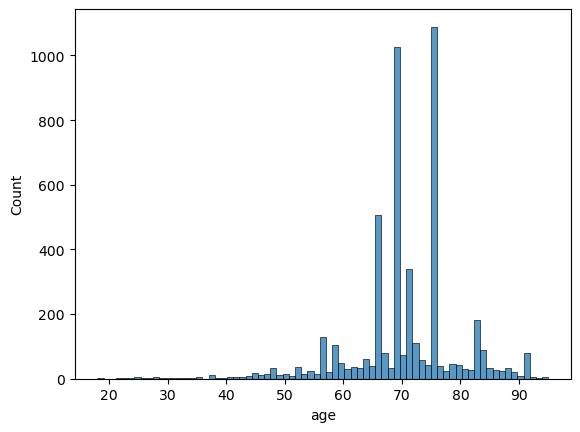

In [469]:
#distributiom of the age
sns.histplot(heart_diagnoses_df, x="age")

In [470]:
# Step 1: Raggruppa per paziente e controlla se ha almeno un gender noto
patients_with_gender_info = (
    heart_diagnoses_df.groupby("subject_id")["gender"]
    .apply(lambda x: x.notna().any())   # True se almeno un record ha gender
)

# Step 2: Filtra i pazienti senza nessuna info sul sesso
patients_without_gender_info = patients_with_gender_info[~patients_with_gender_info]

# Step 3: Conta quanti sono
num_patients_without_gender_info = patients_without_gender_info.shape[0]

print(f"✓ Numero di pazienti senza nessuna info sul sesso: {num_patients_without_gender_info}")



✓ Numero di pazienti senza nessuna info sul sesso: 3128


In [471]:
#metto il gender per chi ha solo un hd mantenendo la proporzione
np.random.seed(42)

def fill_with_proportions(group, global_props=None):
    missing_mask = group['gender'].isna()
    if missing_mask.sum() == 0:
        return group
    
    # Conta valori disponibili
    value_counts = group['gender'].value_counts()
    
    if value_counts.empty:
        # Se non ci sono valori osservati per quell'ICD
        if global_props is not None:
            # Usa proporzioni globali
            choices = np.random.choice(global_props.index, size=missing_mask.sum(), p=global_props.values)
            group.loc[missing_mask, 'gender'] = choices
        else:
            # Altrimenti assegna un default (es. 'M')
            group.loc[missing_mask, 'gender'] = 'M'
    else:
        # Usa proporzioni locali ICD
        proportions = value_counts / value_counts.sum()
        choices = np.random.choice(value_counts.index, size=missing_mask.sum(), p=proportions.values)
        group.loc[missing_mask, 'gender'] = choices
    
    return group

# Calcola proporzioni globali F/M
global_props = heart_diagnoses_df['gender'].value_counts(normalize=True)

# Applica solo ai pazienti con una sola ammissione
df_single_admission = heart_diagnoses_df[heart_diagnoses_df['subject_id'].isin(single_admission_patients)]
df_single_admission = df_single_admission.groupby('icd_code', group_keys=False).apply(fill_with_proportions, global_props=global_props)

# Aggiorna dataset originale
heart_diagnoses_df.update(df_single_admission)

print(f"✓ Missing values in gender (single admission): {df_single_admission['gender'].isna().sum()}")
print(df_single_admission['gender'].value_counts())



✓ Missing values in gender (single admission): 0
gender
M    2357
F    1644
Name: count, dtype: int64


C:\Users\Cominotti\AppData\Local\Temp\ipykernel_20392\2642941352.py:34: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df_single_admission = df_single_admission.groupby('icd_code', group_keys=False).apply(fill_with_proportions, global_props=global_props)


In [472]:
# Conta per ogni paziente se ha almeno un gender noto
patients_with_gender_info = (
    heart_diagnoses_df.groupby("subject_id")["gender"]
    .apply(lambda x: x.notna().any())   # True se almeno un record ha gender
)

# Numero di pazienti con sesso diverso da missing
num_patients_with_gender = patients_with_gender_info.sum()

print(f"✓ Numero di pazienti con almeno un sesso noto: {num_patients_with_gender}")

✓ Numero di pazienti con almeno un sesso noto: 4093


In [473]:
# -------------------------------
# Caso 2: Pazienti con più ammissioni e almeno un gender osservato
# -------------------------------

# Identifica pazienti con più ammissioni
multi_admission_patients = admissions_per_patient[admissions_per_patient['num_admissions'] > 1]['subject_id'].tolist()

# Seleziona solo questi pazienti
df_multi_admission = heart_diagnoses_df[heart_diagnoses_df['subject_id'].isin(multi_admission_patients)]

# Trova il gender osservato per ciascun paziente (se esiste almeno uno)
observed_gender_per_patient = (
    df_multi_admission[df_multi_admission['gender'].notna()]
    .groupby('subject_id')['gender']
    .first()   # usa il primo valore osservato
    .reset_index()
    .rename(columns={'gender': 'patient_observed_gender'})
)

# Merge nel dataset
heart_diagnoses_df = heart_diagnoses_df.merge(observed_gender_per_patient, on='subject_id', how='left')

# Mask: multi-admission, gender mancante, ma con almeno un gender osservato
mask_multi_admission = heart_diagnoses_df['subject_id'].isin(multi_admission_patients)
mask_missing_gender = heart_diagnoses_df['gender'].isna()
mask_has_observed = heart_diagnoses_df['patient_observed_gender'].notna()

rows_to_fill_multi = heart_diagnoses_df[mask_multi_admission & mask_missing_gender & mask_has_observed]

# Copia il gender osservato dove manca
for idx in rows_to_fill_multi.index:
    heart_diagnoses_df.loc[idx, 'gender'] = heart_diagnoses_df.loc[idx, 'patient_observed_gender']

print(f"✓ Missing values in gender (multi admission con info): {rows_to_fill_multi.shape[0]}")
print(heart_diagnoses_df['gender'].value_counts())
heart_diagnoses_df = heart_diagnoses_df.drop(columns=['patient_observed_gender'])


✓ Missing values in gender (multi admission con info): 0
gender
M    2456
F    1736
Name: count, dtype: int64


In [474]:
# Conta per ogni paziente se ha almeno un gender noto
patients_with_gender_info = (
    heart_diagnoses_df.groupby("subject_id")["gender"]
    .apply(lambda x: x.notna().any())   # True se almeno un record ha gender
)

# Numero di pazienti con sesso diverso da missing
num_patients_with_gender = patients_with_gender_info.sum()

print(f"✓ Numero di pazienti con almeno un sesso noto: {num_patients_with_gender}")


✓ Numero di pazienti con almeno un sesso noto: 4093


osservazione: il numero di pazienti con almeno un gender noto rimane 4093 , ma se guardo i risultati M e F ho rimepito caselle, che corrisnodno pero ad un paziente che aveva gia un gender noto

In [475]:
#caso3:# Caso 3: Pazienti con più ammissioni e nessun sesso osservato → imputazione con estrazione casuale secondo  proporzioni globali
patients_without_gender = (
    heart_diagnoses_df.groupby("subject_id")["gender"]
    .apply(lambda x: x.notna().any())
)
patients_without_gender = patients_without_gender[~patients_without_gender].index.tolist()

df_multi_no_gender = heart_diagnoses_df[heart_diagnoses_df['subject_id'].isin(patients_without_gender)]

# Step 2: Calcola proporzioni globali F/M
global_props = heart_diagnoses_df['gender'].value_counts(normalize=True)

# Step 3: Imputazione proporzionale per ICD code
df_multi_no_gender = df_multi_no_gender.groupby('icd_code', group_keys=False).apply(fill_with_proportions, global_props=global_props)

# Step 4: Aggiorna dataset originale
heart_diagnoses_df.update(df_multi_no_gender)

print(f"✓ Missing values in gender (multi admission senza info): {df_multi_no_gender['gender'].isna().sum()}")
print(df_multi_no_gender['gender'].value_counts())

✓ Missing values in gender (multi admission senza info): 0
gender
M    377
F    295
Name: count, dtype: int64


C:\Users\Cominotti\AppData\Local\Temp\ipykernel_20392\2913042964.py:14: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df_multi_no_gender = df_multi_no_gender.groupby('icd_code', group_keys=False).apply(fill_with_proportions, global_props=global_props)


In [476]:
# Conta per ogni paziente se ha almeno un gender noto
patients_with_gender_info = (
    heart_diagnoses_df.groupby("subject_id")["gender"]
    .apply(lambda x: x.notna().any())   # True se almeno un record ha gender
)

# Numero di pazienti con sesso diverso da missing
num_patients_with_gender = patients_with_gender_info.sum()

print(f"✓ Numero di pazienti con almeno un sesso noto: {num_patients_with_gender}")

✓ Numero di pazienti con almeno un sesso noto: 4392


In [477]:
icd_gender_counts = heart_diagnoses_df.groupby(['icd_code', 'gender']).size().unstack(fill_value=0)
icd_gender_counts['Total'] = heart_diagnoses_df.groupby('icd_code').size()

# Rinomina le colonne
icd_gender_counts.columns = ['Female', 'Male', 'Total']

# Ordina per Total (decrescente)
icd_gender_counts = icd_gender_counts.sort_values('Total', ascending=False)

print("=== Gender Distribution per ICD Code ===\n")
print(icd_gender_counts)

=== Gender Distribution per ICD Code ===

          Female  Male  Total
icd_code                     
I50          705   742   1447
I21          522   912   1434
I25          208   437    645
I48          214   224    438
I35           74   157    231
I31           84    69    153
I47           51    79    130
I30           46    37     83
I44           38    32     70
I34           24    26     50
I33            9    29     38
I20           16    20     36
I49           15    20     35
I42           14    19     33
I40            2    14     16
I24            2    10     12
I45            1     4      5
I22            5     0      5
I46            0     2      2
I36            1     0      1


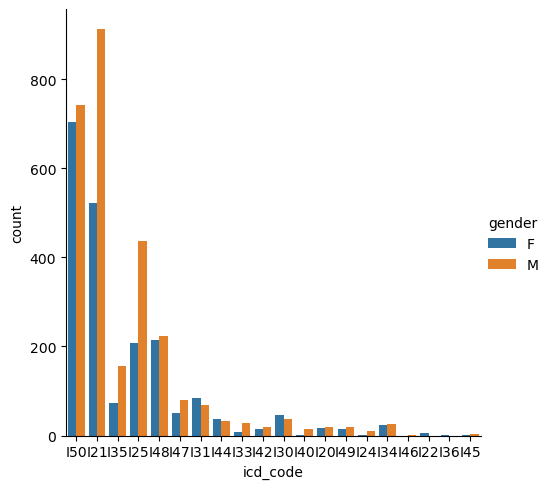

In [478]:
#to visualize the number of female and men for each icd_code
sns.catplot(data=heart_diagnoses_df, x="icd_code", hue="gender",kind="count")

In [479]:
#drop columns that have info achieved in another coloumns 
heart_diagnoses_df=heart_diagnoses_df.drop(columns=["note_id","subject_id_dx"])


In [480]:

#cleaning charttime column : drop the rows where there is an error between charttime and storetime
heart_diagnoses_df = heart_diagnoses_df[heart_diagnoses_df["charttime"] <= heart_diagnoses_df["storetime"]]
#for time analysis i choose to keep only the charttime column and drop the others
heart_diagnoses_df=heart_diagnoses_df.drop(columns=["storetime"])


In [481]:
#final dataset analysis
print("Shape of heart diagnoses dataset:",)
heart_diagnoses_df.shape
print("Info of heart diagnoses dataset:")
heart_diagnoses_df.info()
heart_diagnoses_df_none=du.get_cols_with_none(heart_diagnoses_df)
print("Missing values in each column of heart diagnoses dataset:\n",heart_diagnoses_df_none)
print("Basic statistics of heart diagnoses dataset:")
du.get_basic_stats(heart_diagnoses_df)


Shape of heart diagnoses dataset:
Info of heart diagnoses dataset:
<class 'pandas.core.frame.DataFrame'>
Index: 4855 entries, 0 to 4863
Data columns (total 21 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   subject_id       4855 non-null   int64  
 1   hadm_id          4855 non-null   int64  
 2   note_type        4855 non-null   object 
 3   note_seq         4855 non-null   int64  
 4   charttime        4855 non-null   object 
 5   HPI              4855 non-null   object 
 6   physical_exam    4855 non-null   object 
 7   chief_complaint  4843 non-null   object 
 8   invasions        4843 non-null   object 
 9   X-ray            4855 non-null   int64  
 10  CT               4855 non-null   int64  
 11  Ultrasound       4855 non-null   int64  
 12  CATH             4855 non-null   int64  
 13  ECG              4855 non-null   int64  
 14  MRI              4855 non-null   int64  
 15  reports          4855 non-null   object 
 16

,X-ray,CT,Ultrasound,CATH,ECG,MRI,age,anchor_year
count,4855.0,4855.0,4855.0,4855.0,4855.0,4855.0,4855.000000,1362.000000
mean,0.0,0.0,0.0,0.0,0.0,0.0,70.275386,2155.616006
std,0.0,0.0,0.0,0.0,0.0,0.0,9.320638,23.408053
min,0.0,0.0,0.0,0.0,0.0,0.0,18.000000,2110.000000
25%,0.0,0.0,0.0,0.0,0.0,0.0,66.000000,2136.000000
50%,0.0,0.0,0.0,0.0,0.0,0.0,70.000000,2157.000000
75%,0.0,0.0,0.0,0.0,0.0,0.0,75.000000,2174.000000
max,0.0,0.0,0.0,0.0,0.0,0.0,95.000000,2206.000000


In [482]:
# mean and median age for each icd_code
icd_stats = heart_diagnoses_df.groupby('icd_code')['age'].agg(['mean', 'median']).reset_index()
icd_stats.columns = ['icd_code', 'mean_age', 'median_age']
print("Mean and median age for each ICD code:\n", icd_stats)

Mean and median age for each ICD code:
    icd_code   mean_age  median_age
0       I20  57.027778        60.0
1       I21  68.951433        69.0
2       I22  87.000000        90.0
3       I24  69.333333        69.0
4       I25  66.209502        66.0
5       I30  59.602410        59.0
6       I31  57.794118        57.0
7       I33  57.236842        59.0
8       I34  71.200000        71.0
9       I35  81.746753        83.0
10      I36  60.000000        60.0
11      I40  49.562500        52.0
12      I42  51.227273        48.0
13      I44  82.333333        84.0
14      I45  71.000000        70.0
15      I46  70.000000        70.0
16      I47  68.965385        69.0
17      I48  71.116438        71.0
18      I49  63.942857        64.0
19      I50  74.194464        75.0


<Axes: xlabel='icd_code', ylabel='Count'>

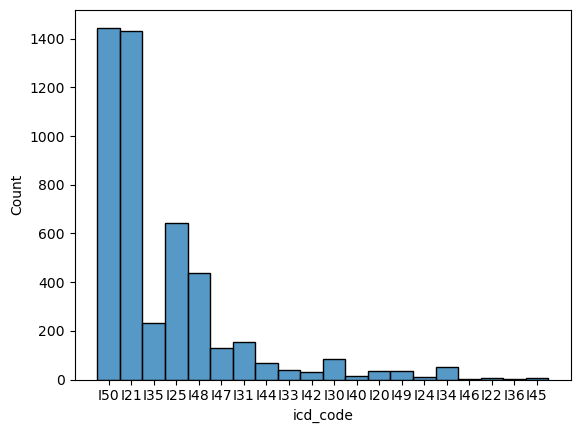

In [483]:
# visualize the new icd_code distribution
sns.histplot(heart_diagnoses_df, x="icd_code")


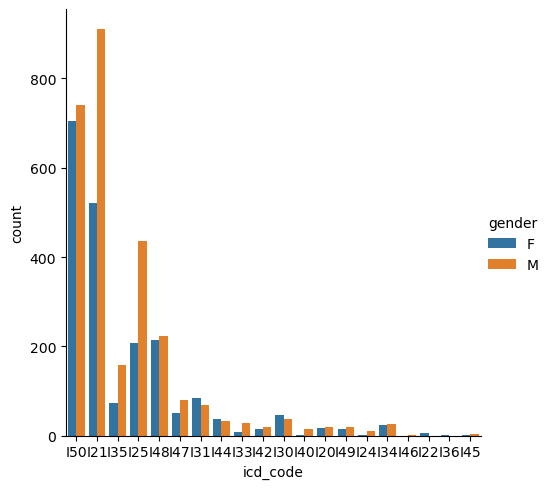

In [484]:
# visualize the number of female and men for each icd_code
sns.catplot(data=heart_diagnoses_df, x="icd_code", hue="gender",kind="count")

<Axes: xlabel='icd_code', ylabel='age'>

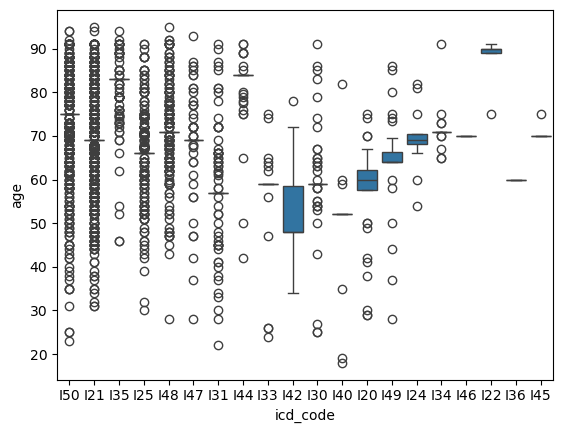

In [485]:
# visualize for each icd_code the age of the patient 
sns.boxplot(data=heart_diagnoses_df,x="icd_code",y="age")

In [486]:
print(heart_diagnoses_df['subject_id'].nunique())
heart_diagnoses_df.to_csv("../../data/processed/hd.csv", index=False)

4384
